In [1]:
# Install (Colab already has most libraries; these two may be missing)
!pip install -q lightgbm statsmodels

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import warnings

from sklearn.metrics import mean_absolute_error, mean_squared_error
import lightgbm as lgb
import statsmodels.api as sm

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

SEED = 42
np.random.seed(SEED)

print("Setup complete")
print("pandas", pd.__version__, "| lightgbm", lgb.__version__)

Setup complete
pandas 2.2.3 | lightgbm 4.6.0


In [2]:
import os, zipfile, urllib.request

url = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"
if not os.path.exists("household_power_consumption.txt"):
    urllib.request.urlretrieve(url, "data.zip")
    with zipfile.ZipFile("data.zip") as z:
        z.extractall(".")

raw = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],      # the dataset marks missing values with '?'
    low_memory=False,
)
print(raw.shape)
raw.head()

(2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [3]:
df = raw.copy()
df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S"
)
df = df.drop(columns=["Date", "Time"]).set_index("datetime").sort_index()

df = df.rename(columns={
    "Global_active_power": "gap_kw",
    "Global_reactive_power": "grp_kw",
    "Voltage": "voltage",
    "Global_intensity": "intensity",
    "Sub_metering_1": "kitchen",
    "Sub_metering_2": "laundry",
    "Sub_metering_3": "heater_ac",
})

print(df.index.min(), "->", df.index.max())
print("Duplicate timestamps:", df.index.duplicated().sum())
print("Rows:", len(df))

2006-12-16 17:24:00 -> 2010-11-26 21:02:00
Duplicate timestamps: 0
Rows: 2075259


In [4]:
missing = df["gap_kw"].isna()
print(f"Missing minutes: {missing.sum():,} ({missing.mean()*100:.2f}%)")

# Find consecutive runs of missing minutes
run_id = (missing != missing.shift()).cumsum()
runs = missing.groupby(run_id).agg(["first", "size"])
gaps = runs[runs["first"]].sort_values("size", ascending=False)
print("Number of gap episodes:", len(gaps))
print("Longest gaps (minutes):", gaps["size"].head(8).tolist())

Missing minutes: 25,979 (1.25%)
Number of gap episodes: 71
Longest gaps (minutes): [7226, 5237, 3723, 3305, 3129, 2027, 891, 83]


In [5]:
# Global_active_power is in kW (minute average): kW * 1000 / 60 = Wh used in that minute
df["total_wh"] = df["gap_kw"] * 1000 / 60
df["other"] = df["total_wh"] - (df["kitchen"] + df["laundry"] + df["heater_ac"])
print(df["other"].describe())
print("Negative 'other' values:", (df["other"] < 0).sum())

count    2.049280e+06
mean     9.314693e+00
std      9.585916e+00
min     -2.400000e+00
25%      3.800000e+00
50%      5.500000e+00
75%      1.036667e+01
max      1.248333e+02
Name: other, dtype: float64
Negative 'other' values: 1050


In [6]:
energy_cols = ["total_wh", "kitchen", "laundry", "heater_ac", "other"]
other_cols = ["gap_kw", "grp_kw", "voltage", "intensity"]

hourly_mean = df[energy_cols + other_cols].resample("h").mean()
valid_minutes = df["gap_kw"].resample("h").count()

# Require at least 30 valid minutes in an hour, else mark the hour as missing
hourly_mean[valid_minutes < 30] = np.nan

hourly = hourly_mean.copy()
hourly[energy_cols] = hourly_mean[energy_cols] * 60      # mean Wh/min -> Wh per hour

hourly["demand_kwh"] = hourly["total_wh"] / 1000         # kWh per hour
hourly["other"] = hourly["other"].clip(lower=0)

print(hourly.shape)
print("Missing hours:", hourly["demand_kwh"].isna().sum())
hourly.head()

(34589, 10)
Missing hours: 432


,total_wh,kitchen,laundry,heater_ac,other,gap_kw,grp_kw,voltage,intensity,demand_kwh
datetime,,,,,,,,,,
2006-12-16 17:00:00,4222.888889,0.0,31.666667,1011.666667,3179.555556,4.222889,0.229000,234.643889,18.100000,4.222889
2006-12-16 18:00:00,3632.200000,0.0,403.000000,1012.000000,2217.200000,3.632200,0.080033,234.580167,15.600000,3.632200
2006-12-16 19:00:00,3400.233333,0.0,86.000000,1001.000000,2313.233333,3.400233,0.085233,233.232500,14.503333,3.400233
2006-12-16 20:00:00,3268.566667,0.0,0.000000,1007.000000,2261.566667,3.268567,0.075100,234.071500,13.916667,3.268567
2006-12-16 21:00:00,3056.466667,0.0,25.000000,1033.000000,1998.466667,3.056467,0.076667,237.158667,13.046667,3.056467


In [7]:
cols_to_fill = ["demand_kwh", "kitchen", "laundry", "heater_ac", "other", "voltage"]

# Rule 1: short gaps (up to 3 hours): linear interpolation
for c in cols_to_fill:
    hourly[c] = hourly[c].interpolate(method="linear", limit=3, limit_area="inside")

# Rule 2: longer gaps: use the value from the same hour one week earlier
for c in cols_to_fill:
    hourly[c] = hourly[c].fillna(hourly[c].shift(168))

# Anything still missing (e.g. very long gaps with a missing previous week)
print("Still missing after filling:\n", hourly[cols_to_fill].isna().sum())

Still missing after filling:
 demand_kwh    0
kitchen       0
laundry       0
heater_ac     0
other         0
voltage       0
dtype: int64


Range: 2006-12-16 17:00:00 -> 2010-11-26 21:00:00
Expected hours: 34589
Actual hours:   34589
Missing demand: 0
Max mismatch (kWh): 0.0


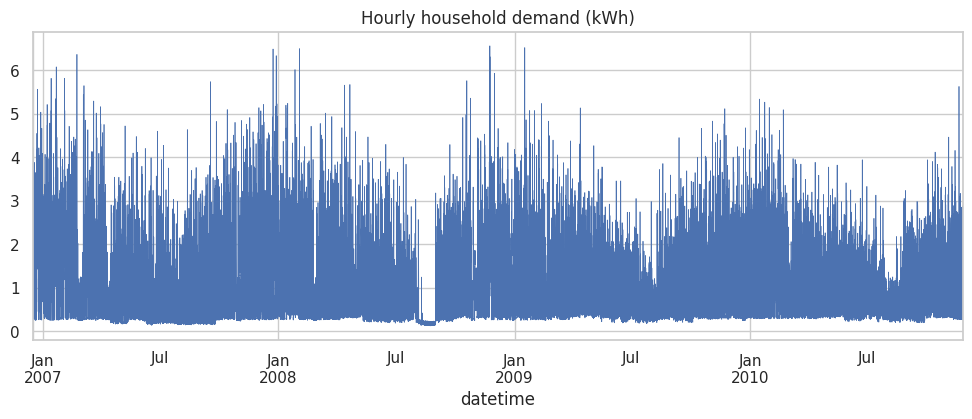

,demand_kwh
count,34589.000000
mean,1.089222
std,0.896409
min,0.124000
25%,0.341167
50%,0.799867
75%,1.577500
max,6.560533


In [8]:
print("Range:", hourly.index.min(), "->", hourly.index.max())
print("Expected hours:", len(pd.date_range(hourly.index.min(), hourly.index.max(), freq="h")))
print("Actual hours:  ", len(hourly))
print("Missing demand:", hourly["demand_kwh"].isna().sum())

# Sanity check: sub-meters + other should add up to the total
check = (hourly[["kitchen", "laundry", "heater_ac", "other"]].sum(axis=1) / 1000 - hourly["demand_kwh"]).abs()
print("Max mismatch (kWh):", round(check.max(), 4))

hourly["demand_kwh"].plot(title="Hourly household demand (kWh)", linewidth=0.5)
plt.show()
hourly["demand_kwh"].describe()

In [10]:
hourly["imputed"] = (valid_minutes < 30).reindex(hourly.index).fillna(True)
print("Imputed hours:", hourly["imputed"].sum(), f"({hourly['imputed'].mean()*100:.2f}%)")
print("Imputed hours in last 3 months:", hourly.loc["2010-08-26":, "imputed"].sum())

Imputed hours: 432 (1.25%)
Imputed hours in last 3 months: 88


In [11]:
print("Missing right before ffill:", hourly[cols_to_fill].isna().sum().sum())

Missing right before ffill: 0


In [15]:
from google.colab import drive
drive.mount("/content/drive")
hourly.to_csv("/content/drive/MyDrive/energy_hourly_clean.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
test_start = "2010-08-26"
test_mask = (hourly.index >= test_start) & (~hourly["imputed"])
print("Test hours total:", (hourly.index >= test_start).sum())
print("Test hours used for scoring:", test_mask.sum())

# Which outage caused the 88 hours?
t = hourly.loc[test_start:, "imputed"]
runs = (t != t.shift()).cumsum()
print(t[t].groupby(runs[t]).agg(lambda s: (s.index.min(), s.index.max(), len(s))))

Test hours total: 2230
Test hours used for scoring: 2142
imputed
2    (2010-09-25 04:00:00, 2010-09-28 18:00:00, 87)
4     (2010-11-26 21:00:00, 2010-11-26 21:00:00, 1)
Name: imputed, dtype: object


In [14]:
hourly["demand_kwh"].describe()

,demand_kwh
count,34589.000000
mean,1.089222
std,0.896409
min,0.124000
25%,0.341167
50%,0.799867
75%,1.577500
max,6.560533


# Phase 2

In [16]:
import requests, time

URL = "https://archive-api.open-meteo.com/v1/archive"
VARS = "temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,shortwave_radiation"

ranges = [("2006-12-15", "2006-12-31"),
          ("2007-01-01", "2007-12-31"),
          ("2008-01-01", "2008-12-31"),
          ("2009-01-01", "2009-12-31"),
          ("2010-01-01", "2010-11-27")]   # one day of padding at each end

frames = []
for start, end in ranges:
    params = {
        "latitude": 48.78, "longitude": 2.29,
        "start_date": start, "end_date": end,
        "hourly": VARS,
        "timezone": "Europe/Paris",
    }
    r = requests.get(URL, params=params, timeout=60)
    r.raise_for_status()
    frames.append(pd.DataFrame(r.json()["hourly"]))
    time.sleep(1)                     # be polite to the free API

weather = pd.concat(frames, ignore_index=True)
weather["time"] = pd.to_datetime(weather["time"])
weather = (weather.drop_duplicates("time")
                  .set_index("time").sort_index()
                  .rename(columns={
                      "temperature_2m": "temp_c",
                      "relative_humidity_2m": "humidity_pct",
                      "wind_speed_10m": "wind_kmh",
                      "cloud_cover": "cloud_pct",
                      "shortwave_radiation": "solar_wm2"}))

print(weather.shape)
print(weather.index.min(), "->", weather.index.max())
weather.describe().round(2)

(34656, 5)
2006-12-15 00:00:00 -> 2010-11-27 23:00:00


,temp_c,humidity_pct,wind_kmh,cloud_pct,solar_wm2
count,34656.00,34656.00,34656.00,34656.00,34656.00
mean,11.17,76.64,12.87,66.13,134.44
std,6.98,15.26,6.43,36.86,204.66
min,-10.50,23.00,0.00,0.00,0.00
25%,6.20,66.00,8.00,34.00,0.00
50%,11.20,80.00,11.60,83.00,7.00
75%,16.20,89.00,16.60,100.00,215.00
max,34.80,100.00,51.70,100.00,908.00


In [17]:
# 1. Value ranges should be physically plausible for Paris
print(weather[["temp_c","humidity_pct","wind_kmh","cloud_pct","solar_wm2"]].agg(["min","max"]).round(1))

# 2. Missing values in the raw weather
print("Missing:\n", weather.isna().sum())

# 3. Monthly mean temperature: should be about 4-5 C in Jan and about 19-20 C in Jul/Aug
weather["temp_c"].groupby(weather.index.month).mean().round(1)

     temp_c  humidity_pct  wind_kmh  cloud_pct  solar_wm2
min   -10.5            23       0.0          0        0.0
max    34.8           100      51.7        100      908.0
Missing:
 temp_c          0
humidity_pct    0
wind_kmh        0
cloud_pct       0
solar_wm2       0
dtype: int64


,temp_c
time,
1,3.6
2,4.9
3,6.7
4,11.2
5,14.3
6,17.1
7,19.1
8,18.5
9,15.1


In [18]:
data = hourly.join(weather[["temp_c","humidity_pct","wind_kmh","cloud_pct","solar_wm2"]], how="left")

wcols = ["temp_c","humidity_pct","wind_kmh","cloud_pct","solar_wm2"]
print("Rows before/after join:", len(hourly), len(data))
print("Missing weather values after join:\n", data[wcols].isna().sum())

Rows before/after join: 34589 34589
Missing weather values after join:
 temp_c          0
humidity_pct    0
wind_kmh        0
cloud_pct       0
solar_wm2       0
dtype: int64


In [19]:
data[wcols] = data[wcols].interpolate(method="linear", limit=3, limit_area="inside")
print("Remaining missing:", data[wcols].isna().sum().sum())

Remaining missing: 0


Summer solar peak hour (local): 14
Winter solar peak hour (local): 14


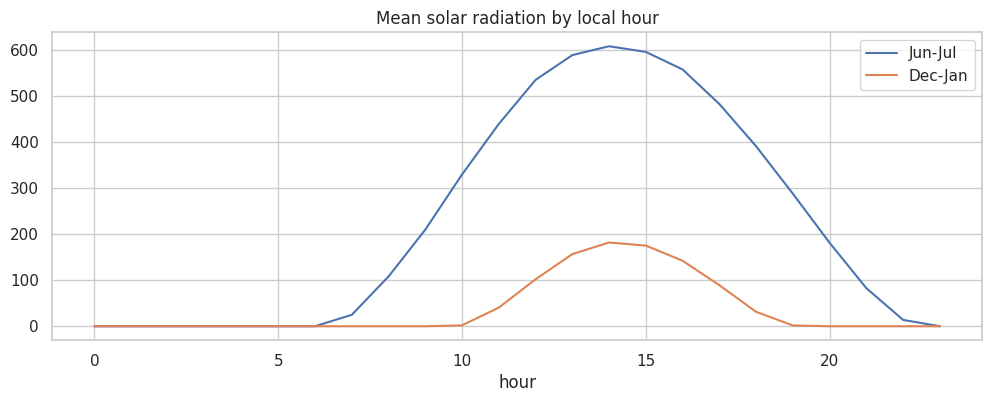

In [20]:
d = data.copy()
d["hour"] = d.index.hour

summer = d[d.index.month.isin([6, 7])].groupby("hour")["solar_wm2"].mean()
winter = d[d.index.month.isin([12, 1])].groupby("hour")["solar_wm2"].mean()
print("Summer solar peak hour (local):", summer.idxmax())
print("Winter solar peak hour (local):", winter.idxmax())

summer.plot(label="Jun-Jul"); winter.plot(label="Dec-Jan")
plt.legend(); plt.title("Mean solar radiation by local hour"); plt.show()

In [21]:
print(data[["demand_kwh"] + wcols].corr()["demand_kwh"].round(3))

demand_kwh      1.000
temp_c         -0.190
humidity_pct    0.055
wind_kmh        0.060
cloud_pct       0.058
solar_wm2      -0.067
Name: demand_kwh, dtype: float64


In [23]:
def daylight_window(months):
    sub = weather[weather.index.month.isin(months)]
    lit = sub[sub["solar_wm2"] > 5]
    by_day = lit.groupby(lit.index.date).apply(
        lambda x: pd.Series({"first_lit": x.index.hour.min(), "last_lit": x.index.hour.max()}))
    m = by_day.mean()
    m["midpoint"] = (m["first_lit"] + m["last_lit"]) / 2
    return m.round(2)

print("Dec-Jan:\n", daylight_window([12, 1]))
print("Jun-Jul:\n", daylight_window([6, 7]))

Dec-Jan:
 first_lit    10.93
last_lit     18.08
midpoint     14.50
dtype: float64
Jun-Jul:
 first_lit     7.03
last_lit     21.89
midpoint     14.46
dtype: float64


In [24]:
d = data.copy()
d["hour"] = d.index.hour

def ramp_hour(months, threshold_share=0.5):
    prof = d[d.index.month.isin(months) & d.index.dayofweek.isin([0,1,2,3,4])] \
             .groupby("hour")["demand_kwh"].mean()
    night = prof.loc[2:4].mean()
    morning_peak = prof.loc[5:10].max()
    level = night + threshold_share * (morning_peak - night)
    return prof.loc[5:11][prof.loc[5:11] >= level].index.min(), prof.round(2)

w_hour, w_prof = ramp_hour([12, 1, 2])
s_hour, s_prof = ramp_hour([6, 7, 8])
print("Winter morning ramp hour:", w_hour)
print("Summer morning ramp hour:", s_hour)

pd.concat([w_prof.rename("winter"), s_prof.rename("summer")], axis=1).loc[4:11]

Winter morning ramp hour: 7
Summer morning ramp hour: 7


,winter,summer
hour,,
4,0.52,0.37
5,0.52,0.36
6,1.06,0.62
7,2.08,1.06
8,1.93,1.16
9,1.61,0.99
10,1.45,0.78
11,1.43,0.70


In [25]:
# preview only; run after we decide the target clock
params["timezone"] = "UTC"   # re-fetch all five ranges with this, then:
# weather.index = weather.index.tz_localize("UTC").tz_convert("Etc/GMT-1").tz_localize(None)   # fixed CET
# or "Europe/Paris" for true local time

In [26]:
data.to_csv("/content/drive/MyDrive/energy_weather_hourly.csv")
data.shape

(34589, 16)

In [27]:
frames = []
for start, end in ranges:
    params = {
        "latitude": 48.78, "longitude": 2.29,
        "start_date": start, "end_date": end,
        "hourly": VARS,
        "timezone": "UTC",
    }
    r = requests.get(URL, params=params, timeout=60)
    r.raise_for_status()
    js = r.json()
    print(start, "utc_offset_seconds:", js.get("utc_offset_seconds"))
    frames.append(pd.DataFrame(js["hourly"]))
    time.sleep(1)

w = pd.concat(frames, ignore_index=True)
w["time"] = pd.to_datetime(w["time"])
w = (w.drop_duplicates("time").set_index("time").sort_index()
       .rename(columns={"temperature_2m": "temp_c", "relative_humidity_2m": "humidity_pct",
                        "wind_speed_10m": "wind_kmh", "cloud_cover": "cloud_pct",
                        "shortwave_radiation": "solar_wm2"}))
weather_utc = w.copy()

# Step 1: sanity check in UTC. Solar noon in Paris is about 11:50 UTC all year,
# so the daylight midpoint should be about the same in both seasons.
def daylight_midpoint(df, months):
    sub = df[df.index.month.isin(months) & (df["solar_wm2"] > 5)]
    g = sub.groupby(sub.index.date).apply(lambda x: (x.index.hour.min() + x.index.hour.max()) / 2)
    return round(g.mean(), 2)

print("UTC midpoint Dec-Jan:", daylight_midpoint(weather_utc, [12, 1]))
print("UTC midpoint Jun-Jul:", daylight_midpoint(weather_utc, [6, 7]))

2006-12-15 utc_offset_seconds: 0
2007-01-01 utc_offset_seconds: 0
2008-01-01 utc_offset_seconds: 0
2009-01-01 utc_offset_seconds: 0
2010-01-01 utc_offset_seconds: 0
UTC midpoint Dec-Jan: 12.5
UTC midpoint Jun-Jul: 12.46


In [28]:
w_local = weather_utc.copy()
w_local.index = (w_local.index.tz_localize("UTC")
                              .tz_convert("Europe/Paris")
                              .tz_localize(None))          # naive local clock, like the energy index

# Autumn clock change creates one duplicate hour; spring change creates one missing hour
w_local = w_local[~w_local.index.duplicated(keep="first")]
full = pd.date_range(w_local.index.min(), w_local.index.max(), freq="h")
w_local = w_local.reindex(full).interpolate(limit=2)

print("Daylight midpoint (local), Dec-Jan:", daylight_midpoint(w_local, [12, 1]))
print("Daylight midpoint (local), Jun-Jul:", daylight_midpoint(w_local, [6, 7]))

Daylight midpoint (local), Dec-Jan: 13.5
Daylight midpoint (local), Jun-Jul: 14.46


In [29]:
wcols = ["temp_c", "humidity_pct", "wind_kmh", "cloud_pct", "solar_wm2"]
data = hourly.join(w_local[wcols], how="left")
data[wcols] = data[wcols].interpolate(method="linear", limit=3, limit_area="inside")

print("Rows:", len(data), "| missing weather:", data[wcols].isna().sum().sum())
print(data[["demand_kwh"] + wcols].corr()["demand_kwh"].round(3))

data.to_csv("/content/drive/MyDrive/energy_weather_hourly.csv")

Rows: 34589 | missing weather: 0
demand_kwh      1.000
temp_c         -0.191
humidity_pct    0.061
wind_kmh        0.063
cloud_pct       0.055
solar_wm2      -0.068
Name: demand_kwh, dtype: float64


Phase 3

In [30]:
eda = data.copy()
eda["hour"] = eda.index.hour
eda["weekday"] = eda.index.dayofweek          # 0 = Monday
eda["is_weekend"] = eda["weekday"] >= 5
eda["month"] = eda.index.month
eda["year"] = eda.index.year
eda["date"] = eda.index.date

real = eda[~eda["imputed"]]                    # real meter readings only, for pattern analysis
print(len(eda), "hours total |", len(real), "real (non-imputed)")

34589 hours total | 34157 real (non-imputed)


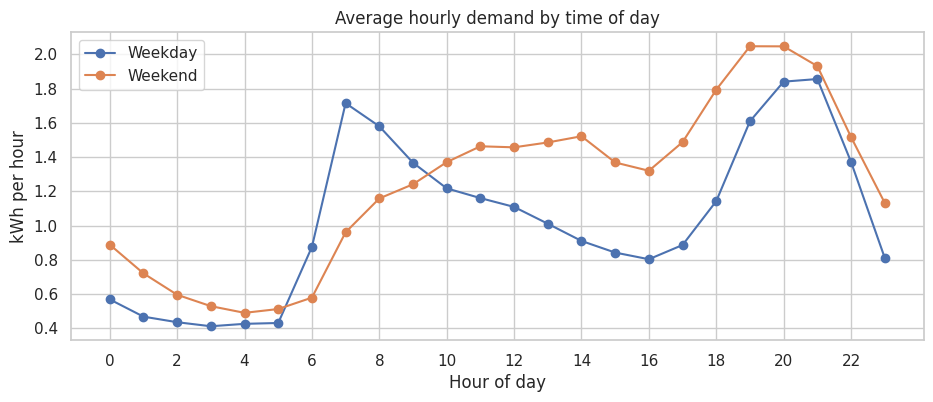

Weekday peak hour: 21 | Weekend peak hour: 19
Weekday avg 18-22h: 1.61 kWh
Overnight avg 2-5h: 0.42 kWh


In [31]:
prof = real.groupby(["is_weekend", "hour"])["demand_kwh"].mean().unstack(0)
prof.columns = ["Weekday", "Weekend"]

ax = prof.plot(marker="o", figsize=(11, 4))
ax.set_title("Average hourly demand by time of day")
ax.set_xlabel("Hour of day"); ax.set_ylabel("kWh per hour"); ax.set_xticks(range(0, 24, 2))
plt.show()

print("Weekday peak hour:", prof["Weekday"].idxmax(), "| Weekend peak hour:", prof["Weekend"].idxmax())
print("Weekday avg 18-22h:", prof.loc[18:21, "Weekday"].mean().round(2), "kWh")
print("Overnight avg 2-5h:", prof.loc[2:4, "Weekday"].mean().round(2), "kWh")

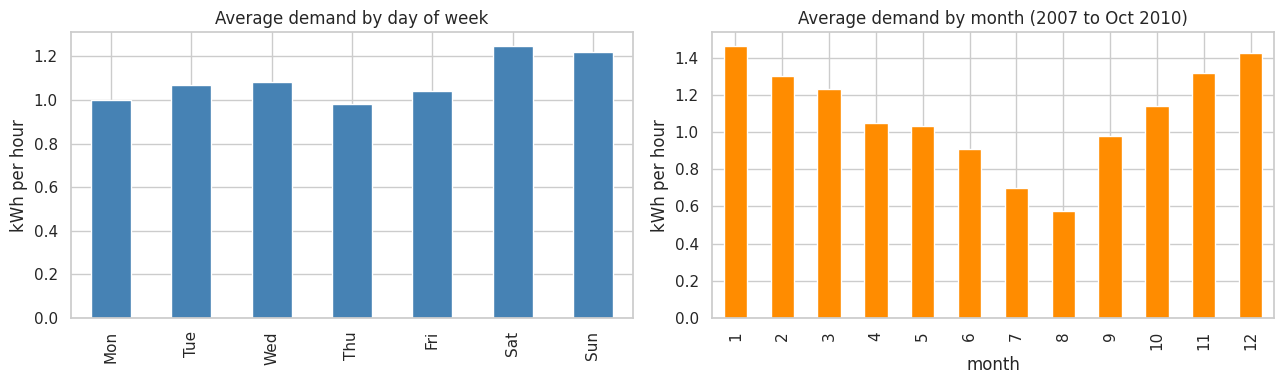

month
1     1.46
2     1.30
3     1.23
4     1.05
5     1.03
6     0.91
7     0.70
8     0.57
9     0.98
10    1.14
11    1.32
12    1.42
Name: demand_kwh, dtype: float64


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

dow = real.groupby("weekday")["demand_kwh"].mean()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow.plot(kind="bar", ax=axes[0], color="steelblue", title="Average demand by day of week")
axes[0].set_ylabel("kWh per hour")

# Use only full calendar years' months: Dec 2006 and Nov 2010 are partial
full = real[(real.index >= "2007-01-01") & (real.index < "2010-11-01")]
mon = full.groupby("month")["demand_kwh"].mean()
mon.plot(kind="bar", ax=axes[1], color="darkorange", title="Average demand by month (2007 to Oct 2010)")
axes[1].set_ylabel("kWh per hour")
plt.tight_layout(); plt.show()

print(mon.round(2))

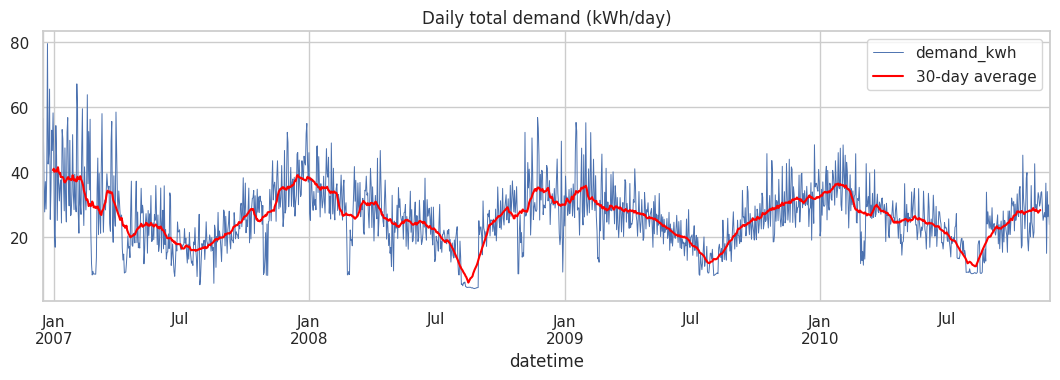

count    1442.0
mean       26.1
std        10.0
min         4.2
25%        19.5
50%        25.9
75%        31.6
max        79.6
Name: demand_kwh, dtype: float64
Lowest 5 days:
 datetime
2008-08-25    4.2
2008-08-23    4.2
2008-08-24    4.2
2008-08-26    4.3
2008-08-27    4.3
Name: demand_kwh, dtype: float64


In [33]:
daily = eda["demand_kwh"].resample("D").sum()
ax = daily.plot(figsize=(13, 3.5), linewidth=0.7, title="Daily total demand (kWh/day)")
daily.rolling(30, center=True).mean().plot(ax=ax, color="red", label="30-day average")
ax.legend(); plt.show()

print(daily.describe().round(1))
print("Lowest 5 days:\n", daily.nsmallest(5).round(1))

Share of total energy (%):
 kitchen       6.2
laundry       7.1
heater_ac    35.5
other        51.1
dtype: float64


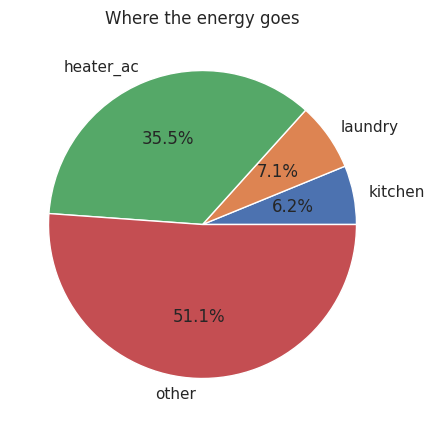

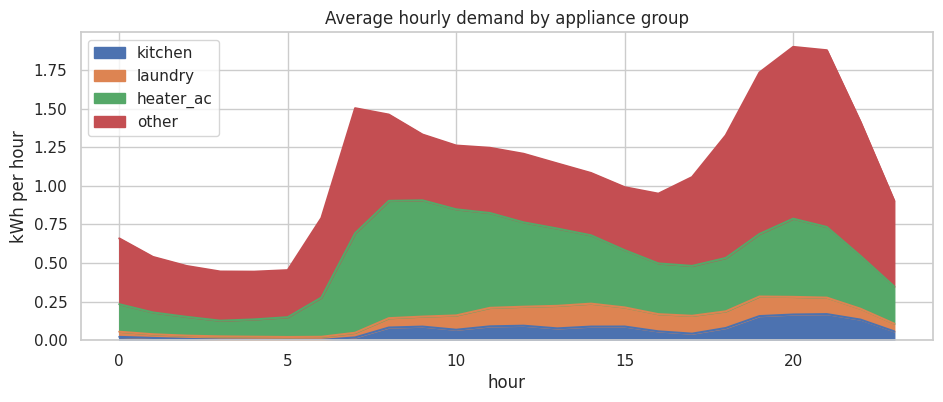

In [34]:
parts = ["kitchen", "laundry", "heater_ac", "other"]
share = eda[parts].sum() / eda[parts].sum().sum() * 100
print("Share of total energy (%):\n", share.round(1))

share.plot(kind="pie", autopct="%1.1f%%", figsize=(5, 5), ylabel="", title="Where the energy goes")
plt.show()

app_profile = real.groupby("hour")[parts].mean() / 1000      # kWh per hour
app_profile.plot.area(figsize=(11, 4), title="Average hourly demand by appliance group")
plt.ylabel("kWh per hour"); plt.show()

In [35]:
peak_hours = [18, 19, 20, 21]
real_tot = real["demand_kwh"].sum()
peak_share = real.loc[real["hour"].isin(peak_hours), "demand_kwh"].sum() / real_tot * 100
print(f"Share of all energy used in 18:00-22:00: {peak_share:.1f}% (4 of 24 hours = 16.7% if flat)")

peak_by_app = (real[real["hour"].isin(peak_hours)][parts].sum() / 1000)
print("Peak-window energy by appliance group (kWh):\n", peak_by_app.round(0))

# Which hour is the daily maximum most often?
daily_peak_hour = real.groupby("date")["demand_kwh"].idxmax().dt.hour
print(daily_peak_hour.value_counts().head(5))

Share of all energy used in 18:00-22:00: 26.1% (4 of 24 hours = 16.7% if flat)
Peak-window energy by appliance group (kWh):
 kitchen       815.0
laundry       649.0
heater_ac    2443.0
other        5838.0
dtype: float64
demand_kwh
20    221
21    212
19    148
7     147
8      87
Name: count, dtype: int64


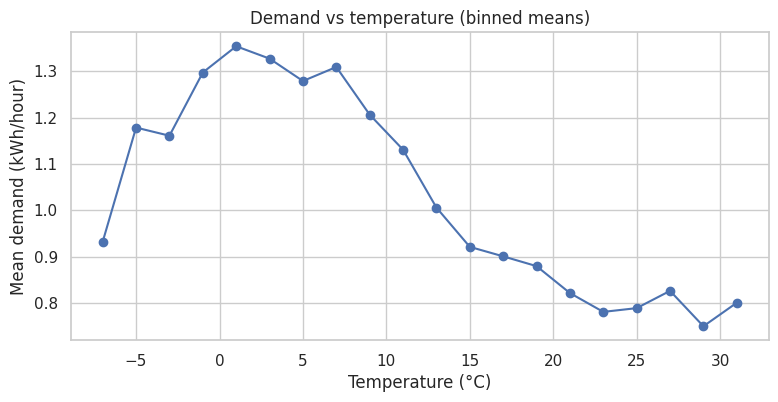

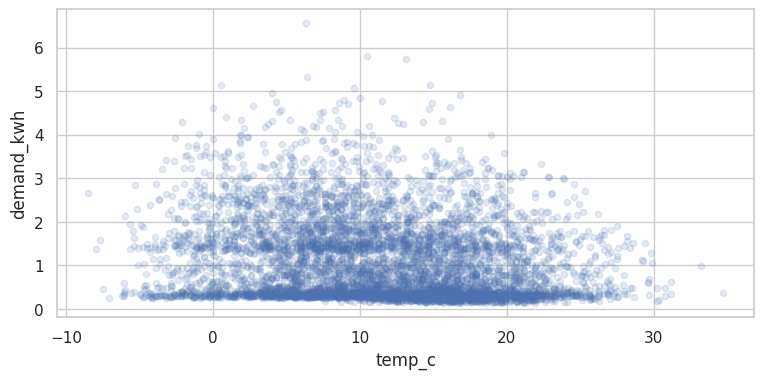

In [36]:
bins = np.arange(-10, 36, 2)
eda["temp_bin"] = pd.cut(eda["temp_c"], bins)
tb = eda.groupby("temp_bin", observed=True)["demand_kwh"].agg(["mean", "count"])
tb = tb[tb["count"] >= 30]                           # skip bins with very few hours
mid = [iv.mid for iv in tb.index]

plt.figure(figsize=(9, 4))
plt.plot(mid, tb["mean"], marker="o")
plt.xlabel("Temperature (°C)"); plt.ylabel("Mean demand (kWh/hour)")
plt.title("Demand vs temperature (binned means)"); plt.show()

eda.sample(6000, random_state=SEED).plot.scatter("temp_c", "demand_kwh", alpha=0.15, figsize=(9, 4))
plt.show()

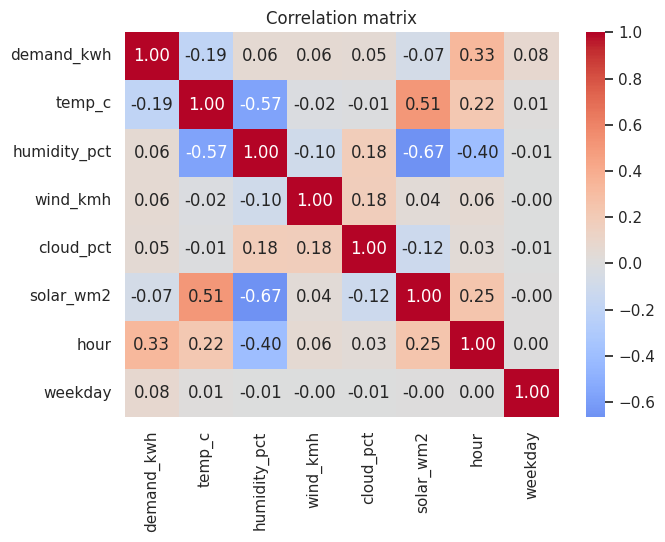

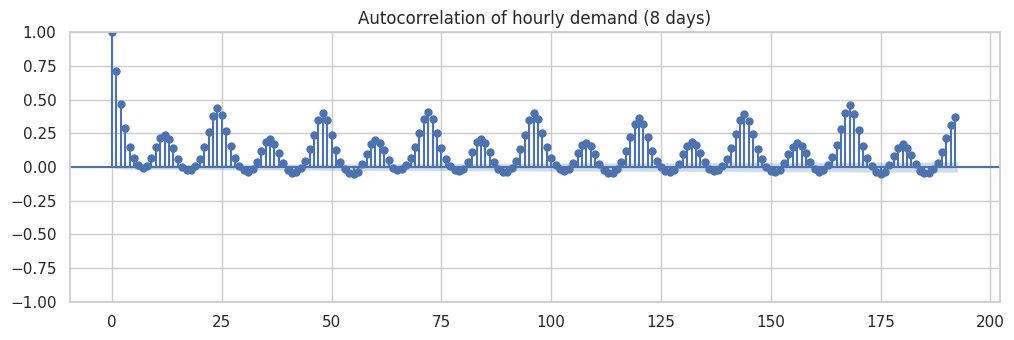

Autocorrelation at lag 1h: 0.713
Autocorrelation at lag 24h: 0.436
Autocorrelation at lag 48h: 0.402
Autocorrelation at lag 168h: 0.466


In [37]:
cols = ["demand_kwh", "temp_c", "humidity_pct", "wind_kmh", "cloud_pct", "solar_wm2", "hour", "weekday"]
plt.figure(figsize=(7, 5))
sns.heatmap(eda[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

from statsmodels.graphics.tsaplots import plot_acf
fig, ax = plt.subplots(figsize=(12, 3.5))
plot_acf(eda["demand_kwh"], lags=24 * 8, ax=ax)
ax.set_title("Autocorrelation of hourly demand (8 days)"); plt.show()

for lag in [1, 24, 48, 168]:
    print(f"Autocorrelation at lag {lag}h:", round(eda["demand_kwh"].autocorr(lag), 3))

In [38]:
# 1. Were the Aug 2008 lowest days real, or imputed copies?
chk = eda.loc["2008-08-22":"2008-08-28"]
print("Imputed share:", round(chk["imputed"].mean(), 3))
print(chk["demand_kwh"].resample("D").sum().round(1))

# 2. Where does the winter rise come from? (monthly mean by appliance group, kWh/h)
print((full.groupby("month")[parts].mean() / 1000).round(2))

# 3. How peak-heavy is each appliance group? (% of its own energy used 18-22h)
own = real[real["hour"].isin(peak_hours)][parts].sum() / real[parts].sum() * 100
print(own.round(1))

# 4. How much of the laundry meter is a constant base (fridge)? And when does heater_ac run?
lau = real["laundry"] / 1000
base = lau.quantile(0.10)
print("Laundry base (10th pct):", round(base, 3), "kWh/h | share above base:",
      round(((lau - base).clip(lower=0).sum()) / lau.sum(), 3))
print((real.groupby("hour")["heater_ac"].mean() / 1000).round(2).tolist())

Imputed share: 0.0
datetime
2008-08-22    4.5
2008-08-23    4.2
2008-08-24    4.2
2008-08-25    4.2
2008-08-26    4.3
2008-08-27    4.3
2008-08-28    4.5
Freq: D, Name: demand_kwh, dtype: float64
       kitchen  laundry  heater_ac  other
month                                    
1         0.08     0.09       0.47   0.82
2         0.07     0.08       0.46   0.69
3         0.08     0.10       0.42   0.64
4         0.06     0.07       0.40   0.51
5         0.07     0.08       0.40   0.48
6         0.08     0.07       0.37   0.38
7         0.04     0.06       0.26   0.34
8         0.03     0.05       0.23   0.26
9         0.07     0.07       0.38   0.45
10        0.06     0.09       0.39   0.59
11        0.08     0.08       0.42   0.73
12        0.08     0.08       0.47   0.79
kitchen      35.4
laundry      24.4
heater_ac    18.5
other        30.6
dtype: float64
Laundry base (10th pct): 0.0 kWh/h | share above base: 1.0
[0.18, 0.14, 0.12, 0.1, 0.11, 0.13, 0.25, 0.64, 0.76, 0.75, 0.69, 0.61

8     0.163
9     0.179
10    0.194
11    0.209
12    0.222
13    0.234
14    0.244
15    0.253
16    0.261
17    0.267
18    0.273
19    0.277
20    0.281
21    0.283
22    0.285
23    0.286
24    0.286
Name: corr_with_resid, dtype: float64


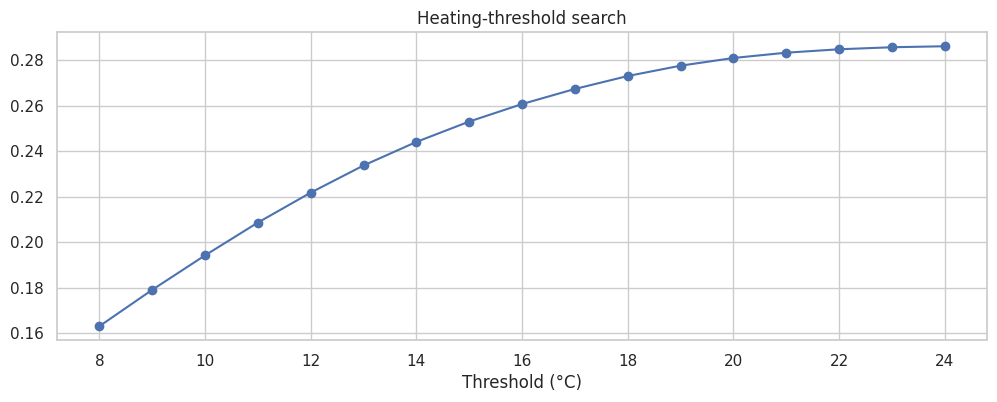

Best threshold: 24


In [39]:
d = eda[~eda["imputed"]].copy()
d = d[~((d.index >= "2008-08-15") & (d.index <= "2008-08-31"))]   # remove the vacation window
d["resid"] = d["demand_kwh"] - d.groupby(["hour", "is_weekend"])["demand_kwh"].transform("mean")

res = pd.Series({T: d["resid"].corr((T - d["temp_c"]).clip(lower=0)) for T in range(8, 25)},
                name="corr_with_resid")
print(res.round(3))
res.plot(marker="o", title="Heating-threshold search"); plt.xlabel("Threshold (°C)"); plt.show()
print("Best threshold:", res.idxmax())

In [40]:
d = eda[~eda["imputed"]].copy()
d = d[~((d.index >= "2008-08-15") & (d.index <= "2008-08-31"))]   # exclude vacation window

# Remove the normal pattern for this hour, day type AND month
grp = d.groupby(["hour", "is_weekend", "month"])
d["resid"] = d["demand_kwh"] - grp["demand_kwh"].transform("mean")
d["tdev"]  = d["temp_c"]    - d.groupby(["hour", "is_weekend", "month"])["temp_c"].transform("mean")

# Two-slope (hinge) model on temperature deviation; pick the breakpoint with the best fit
def fit(T):
    X = np.column_stack([np.ones(len(d)), d["temp_c"], np.maximum(0, d["temp_c"] - T)])
    beta, *_ = np.linalg.lstsq(X, d["resid"], rcond=None)
    sse = ((d["resid"] - X @ beta) ** 2).sum()
    return 1 - sse / ((d["resid"] - d["resid"].mean()) ** 2).sum(), beta

out = pd.DataFrame({T: [fit(T)[0], *fit(T)[1][1:]] for T in range(2, 30)},
                   index=["R2", "slope_below", "slope_change"]).T
print(out.round(4))
print("Best breakpoint:", out["R2"].idxmax())

        R2  slope_below  slope_change
2   0.0016       0.0236       -0.0274
3   0.0014       0.0178       -0.0216
4   0.0012       0.0132       -0.0171
5   0.0010       0.0097       -0.0137
6   0.0010       0.0076       -0.0117
7   0.0009       0.0059       -0.0101
8   0.0008       0.0045       -0.0089
9   0.0007       0.0032       -0.0075
10  0.0006       0.0022       -0.0066
11  0.0005       0.0015       -0.0059
12  0.0005       0.0010       -0.0056
13  0.0004       0.0006       -0.0053
14  0.0004       0.0002       -0.0051
15  0.0004       0.0000       -0.0053
16  0.0004      -0.0002       -0.0054
17  0.0004      -0.0005       -0.0053
18  0.0003      -0.0008       -0.0044
19  0.0002      -0.0011       -0.0030
20  0.0002      -0.0014       -0.0013
21  0.0002      -0.0015        0.0007
22  0.0002      -0.0016        0.0037
23  0.0003      -0.0017        0.0072
24  0.0003      -0.0017        0.0106
25  0.0003      -0.0017        0.0150
26  0.0003      -0.0017        0.0200
27  0.0003  

In [41]:
def fit(T):
    X = np.column_stack([np.ones(len(d)), d["tdev"], np.maximum(0, d["tdev"] - T)])
    beta, *_ = np.linalg.lstsq(X, d["resid"], rcond=None)
    sse = ((d["resid"] - X @ beta) ** 2).sum()
    return 1 - sse / ((d["resid"] - d["resid"].mean()) ** 2).sum(), beta

print("Std of raw temp:", round(d["temp_c"].std(), 2), "| std of tdev:", round(d["tdev"].std(), 2))
out = pd.DataFrame({T: [fit(T)[0], *fit(T)[1][1:]] for T in range(-8, 9)},
                   index=["R2", "slope_below", "slope_change"]).T
print(out.round(4)); print("Best breakpoint:", out["R2"].idxmax())

# Simpler cross-check: one straight line on deviations
print("Linear R2 (tdev only):", round(d["resid"].corr(d["tdev"]) ** 2, 4))

Std of raw temp: 6.95 | std of tdev: 3.49
        R2  slope_below  slope_change
-8  0.0012       0.0823       -0.0888
-7  0.0013       0.0572       -0.0642
-6  0.0014       0.0393       -0.0469
-5  0.0013       0.0242       -0.0322
-4  0.0013       0.0142       -0.0227
-3  0.0011       0.0063       -0.0148
-2  0.0010      -0.0000       -0.0080
-1  0.0009      -0.0044       -0.0022
 0  0.0009      -0.0055       -0.0005
 1  0.0009      -0.0057       -0.0003
 2  0.0009      -0.0058        0.0000
 3  0.0009      -0.0059        0.0003
 4  0.0009      -0.0057       -0.0004
 5  0.0009      -0.0056       -0.0027
 6  0.0009      -0.0057       -0.0014
 7  0.0009      -0.0057       -0.0019
 8  0.0009      -0.0058       -0.0023
Best breakpoint: -6
Linear R2 (tdev only): 0.0009


In [42]:
for name, sub in {"All hours": d,
                  "Evening 18-22h": d[d["hour"].isin([18,19,20,21])],
                  "Winter evening": d[d["hour"].isin([18,19,20,21]) & d["month"].isin([12,1,2])]}.items():
    r = sub["resid"].corr(sub["tdev"])
    slope = np.polyfit(sub["tdev"], sub["resid"], 1)[0]
    print(f"{name:15s} n={len(sub):6d}  corr={r:6.3f}  slope={slope:7.4f} kWh/h per °C")

All hours       n= 33772  corr=-0.029  slope=-0.0058 kWh/h per °C
Evening 18-22h  n=  5637  corr=-0.028  slope=-0.0070 kWh/h per °C
Winter evening  n=  1375  corr= 0.040  slope= 0.0105 kWh/h per °C


Phase 4

In [43]:
!pip install -q holidays
import holidays

fr_holidays = holidays.France(years=range(2006, 2011))
holiday_dates = np.array(list(fr_holidays.keys()))
print(len(holiday_dates), "French public holidays in range")

52 French public holidays in range


In [44]:
def build_features(df):
    """df has demand_kwh and the 5 weather columns, hourly index. Returns features + target."""
    y = df["demand_kwh"]
    idx = df.index
    f = pd.DataFrame(index=idx)
    f["target"] = y

    # ---- Calendar (known in advance, no leakage possible) ----
    f["hour"] = idx.hour
    f["weekday"] = idx.dayofweek
    f["month"] = idx.month
    f["is_weekend"] = (f["weekday"] >= 5).astype(int)
    f["is_holiday"] = np.isin(idx.date, holiday_dates).astype(int)
    f["is_august"] = (f["month"] == 8).astype(int)
    f["hour_sin"] = np.sin(2 * np.pi * f["hour"] / 24)
    f["hour_cos"] = np.cos(2 * np.pi * f["hour"] / 24)
    f["month_sin"] = np.sin(2 * np.pi * f["month"] / 12)
    f["month_cos"] = np.cos(2 * np.pi * f["month"] / 12)

    # ---- Demand history: everything is at least 24 h old ----
    for L in [24, 48, 168]:
        f[f"lag_{L}"] = y.shift(L)
    f["same_hour_mean_7d"] = pd.concat([y.shift(24 * k) for k in range(1, 8)], axis=1).mean(axis=1)

    s = y.shift(24)                                   # the "latest known" series
    f["roll_mean_24"]  = s.rolling(24).mean()         # yesterday's average level
    f["roll_mean_168"] = s.rolling(168).mean()        # last week's average level
    f["roll_std_168"]  = s.rolling(168).std()
    f["roll_max_24"]   = s.rolling(24).max()
    f["recent_ratio"]  = f["roll_mean_24"] / f["roll_mean_168"]   # yesterday vs normal (vacation signal)

    # ---- Weather (assumed available as a forecast; see limitations) ----
    for c in ["temp_c", "humidity_pct", "wind_kmh", "cloud_pct", "solar_wm2"]:
        f[c] = df[c]
    f["hdh_15"] = (15 - df["temp_c"]).clip(lower=0)
    f["hdh_20"] = (20 - df["temp_c"]).clip(lower=0)
    f["temp_roll24"] = df["temp_c"].rolling(24).mean()
    f["temp_change_24"] = df["temp_c"] - df["temp_c"].shift(24)
    return f

wcols = ["temp_c", "humidity_pct", "wind_kmh", "cloud_pct", "solar_wm2"]
feats = build_features(data[["demand_kwh"] + wcols])
feats["imputed"] = data["imputed"]
feats = feats.dropna()                       # drops the first 192 hours (lags and rolling windows need history)
print(feats.shape)

(34398, 30)


In [45]:
calendar_feats = ["hour","weekday","month","is_weekend","is_holiday","is_august",
                  "hour_sin","hour_cos","month_sin","month_cos"]
lag_feats = ["lag_24","lag_48","lag_168","same_hour_mean_7d",
             "roll_mean_24","roll_mean_168","roll_std_168","roll_max_24","recent_ratio"]
weather_feats = ["temp_c","humidity_pct","wind_kmh","cloud_pct","solar_wm2",
                 "hdh_15","hdh_20","temp_roll24","temp_change_24"]

for name, g in [("calendar", calendar_feats), ("history", lag_feats), ("weather", weather_feats)]:
    print(f"{name:9s}: {len(g)} features")
assert set(calendar_feats + lag_feats + weather_feats) | {"target","imputed"} == set(feats.columns)

calendar : 10 features
history  : 9 features
weather  : 9 features


In [46]:
def leakage_test(base_df, T="2009-03-10 12:00"):
    T = pd.Timestamp(T)
    a = build_features(base_df).drop(columns="target")
    d2 = base_df.copy()
    d2.loc[d2.index >= T, "demand_kwh"] += 100.0
    b = build_features(d2).drop(columns="target")

    limit = T + pd.Timedelta(hours=24)
    early = a.index < limit
    same = np.isclose(a[early].values, b[early].values, equal_nan=True).all(axis=0)
    leaked = a.columns[~same].tolist()
    print("Features that changed BEFORE T+24h (should be empty):", leaked)

    late = ~early
    changed = a.columns[~np.isclose(a[late].values, b[late].values, equal_nan=True).all(axis=0)].tolist()
    print("Features that changed AFTER T+24h (history features expected):", changed)
    return leaked

for T in ["2009-03-10 12:00", "2008-11-05 03:00", "2010-07-01 18:00"]:
    assert leakage_test(data[["demand_kwh"] + wcols], T) == [], "LEAKAGE FOUND"
print("Leakage test passed")

Features that changed BEFORE T+24h (should be empty): []
Features that changed AFTER T+24h (history features expected): ['lag_24', 'lag_48', 'lag_168', 'same_hour_mean_7d', 'roll_mean_24', 'roll_mean_168', 'roll_std_168', 'roll_max_24', 'recent_ratio']
Features that changed BEFORE T+24h (should be empty): []
Features that changed AFTER T+24h (history features expected): ['lag_24', 'lag_48', 'lag_168', 'same_hour_mean_7d', 'roll_mean_24', 'roll_mean_168', 'roll_std_168', 'roll_max_24', 'recent_ratio']
Features that changed BEFORE T+24h (should be empty): []
Features that changed AFTER T+24h (history features expected): ['lag_24', 'lag_48', 'lag_168', 'same_hour_mean_7d', 'roll_mean_24', 'roll_mean_168', 'roll_std_168', 'roll_max_24', 'recent_ratio']
Leakage test passed


In [47]:
test_start = pd.Timestamp("2010-08-26")
val_start  = pd.Timestamp("2010-05-26")

train = feats[feats.index < val_start]
val   = feats[(feats.index >= val_start) & (feats.index < test_start)]
test  = feats[feats.index >= test_start]

for n, d_ in [("train", train), ("val", val), ("test", test)]:
    print(f"{n:5s} {d_.index.min().date()} -> {d_.index.max().date()}  rows={len(d_):6d}  imputed={int(d_['imputed'].sum())}")

# Scoring masks: real meter readings only
val_mask  = ~val["imputed"].values
test_mask = ~test["imputed"].values
print("Scored hours: val", val_mask.sum(), "| test", test_mask.sum())

train 2006-12-24 -> 2010-05-25  rows= 29960  imputed=224
val   2010-05-26 -> 2010-08-25  rows=  2208  imputed=120
test  2010-08-26 -> 2010-11-26  rows=  2230  imputed=88
Scored hours: val 2088 | test 2142


In [48]:
tr = train.drop(columns="imputed")
corr = tr.drop(columns="target").corrwith(tr["target"]).sort_values(key=abs, ascending=False)
print(corr.round(3).head(12))

print("\nMissing values:", feats.isna().sum().sum())
print("Infinite values:", np.isinf(feats.drop(columns="imputed")).sum().sum())
print(train[["lag_24","lag_168","same_hour_mean_7d","roll_mean_168","recent_ratio"]].describe().round(2))

same_hour_mean_7d    0.585
lag_168              0.468
lag_24               0.430
lag_48               0.399
hour                 0.339
roll_mean_168        0.292
roll_std_168         0.267
temp_roll24         -0.249
month_cos            0.239
roll_mean_24         0.234
hour_sin            -0.228
roll_max_24          0.213
dtype: float64

Missing values: 0
Infinite values: 0
         lag_24   lag_168  same_hour_mean_7d  roll_mean_168  recent_ratio
count  29960.00  29960.00           29960.00       29960.00      29960.00
mean       1.11      1.11               1.11           1.11          1.00
std        0.92      0.92               0.64           0.33          0.27
min        0.12      0.12               0.15           0.18          0.22
25%        0.34      0.34               0.57           0.89          0.84
50%        0.82      0.82               1.02           1.13          0.98
75%        1.61      1.61               1.53           1.35          1.13
max        6.56      6.56      

In [53]:
feats.to_csv("/content/drive/MyDrive/features_dayahead.csv")

Phase 5

In [54]:
def metrics(y, p, mask, hours=None):
    y, p = np.asarray(y)[mask], np.asarray(p)[mask]
    mae = np.mean(np.abs(y - p))
    out = {"MAE": mae,
           "RMSE": np.sqrt(np.mean((y - p) ** 2)),
           "MAE % of mean": mae / y.mean() * 100,
           "MAPE %": np.mean(np.abs(y - p) / y) * 100}
    if hours is not None:                     # error in the 18-22h window, which the scheduler cares about
        pk = np.isin(np.asarray(hours)[mask], [18, 19, 20, 21])
        out["Peak MAE"] = np.mean(np.abs(y[pk] - p[pk]))
    return pd.Series(out)

yv, hv = val["target"].values, val.index.hour

In [55]:
base = {
    "Mean of training":       np.full(len(val), train["target"].mean()),
    "Yesterday (lag_24)":     val["lag_24"].values,
    "Last week (lag_168)":    val["lag_168"].values,
    "7-day same-hour mean":   val["same_hour_mean_7d"].values,
}
tab = pd.DataFrame({k: metrics(yv, v, val_mask, hv) for k, v in base.items()}).T
print(tab.round(3))
print("Mean validation demand:", round(yv[val_mask].mean(), 3))

                        MAE   RMSE  MAE % of mean   MAPE %  Peak MAE
Mean of training      0.597  0.668         77.369  139.543     0.581
Yesterday (lag_24)    0.402  0.611         52.141   57.461     0.491
Last week (lag_168)   0.452  0.652         58.584   74.617     0.589
7-day same-hour mean  0.365  0.504         47.372   60.769     0.451
Mean validation demand: 0.771


In [56]:
from itertools import product

def fit_lgb(cols, params, seed=SEED, n_est=None):
    m = lgb.LGBMRegressor(objective="regression", metric="l1",
                          n_estimators=n_est or 3000,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                          random_state=seed, verbose=-1, **params)
    if n_est is None:    # early stopping on the validation window
        m.fit(train[cols], train["target"],
              eval_set=[(val[cols], val["target"])],
              callbacks=[lgb.early_stopping(100, verbose=False)])
    else:
        m.fit(train[cols], train["target"])
    return m

all_feats = calendar_feats + lag_feats + weather_feats
grid = [dict(num_leaves=nl, learning_rate=lr, min_child_samples=mc)
        for nl, lr, mc in product([15, 31], [0.03, 0.06], [20, 60])]

rows = []
for g in grid:
    m = fit_lgb(all_feats, g)
    p = m.predict(val[all_feats])
    rows.append({**g, "best_iter": m.best_iteration_, **metrics(yv, p, val_mask, hv)[["MAE", "RMSE"]].to_dict()})
gres = pd.DataFrame(rows).sort_values("MAE")
print(gres.round(4))
best = {k: (int(v) if k != "learning_rate" else float(v))
        for k, v in gres.iloc[0][["num_leaves", "learning_rate", "min_child_samples"]].items()}
print("Chosen parameters:", best)

   num_leaves  learning_rate  min_child_samples  best_iter     MAE    RMSE
7          31           0.06                 60        169  0.3446  0.4696
4          31           0.03                 20        384  0.3454  0.4696
5          31           0.03                 60        404  0.3455  0.4710
6          31           0.06                 20        275  0.3476  0.4737
0          15           0.03                 20        431  0.3485  0.4696
2          15           0.06                 20        314  0.3487  0.4717
1          15           0.03                 60        588  0.3503  0.4717
3          15           0.06                 60        420  0.3506  0.4741
Chosen parameters: {'num_leaves': 31, 'learning_rate': 0.06, 'min_child_samples': 60}


In [57]:
sets = {
    "A. Calendar only":              calendar_feats,
    "B. Calendar + history":         calendar_feats + lag_feats,
    "C. Calendar + history + weather": calendar_feats + lag_feats + weather_feats,
}
preds, results = {}, {}
for name, cols in sets.items():
    ps, its = [], []
    for sd in [42, 7, 123]:
        m = fit_lgb(cols, best, seed=sd)
        ps.append(m.predict(val[cols])); its.append(m.best_iteration_)
    preds[name] = np.mean(ps, axis=0)
    results[name] = metrics(yv, preds[name], val_mask, hv)
    results[name]["best_iter"] = int(np.mean(its))

abl = pd.DataFrame(results).T
print(abl.round(3))

                                   MAE   RMSE  MAE % of mean  MAPE %  \
A. Calendar only                 0.368  0.499         47.729  61.206   
B. Calendar + history            0.340  0.471         44.138  56.168   
C. Calendar + history + weather  0.344  0.470         44.556  57.245   

                                 Peak MAE  best_iter  
A. Calendar only                    0.489      179.0  
B. Calendar + history               0.454      238.0  
C. Calendar + history + weather     0.442      261.0  


In [58]:
def daily_abs_err(p):
    e = pd.Series(np.abs(yv - p), index=val.index)[val_mask]
    return e.groupby(e.index.date).mean()

dB, dC = daily_abs_err(preds["B. Calendar + history"]), daily_abs_err(preds["C. Calendar + history + weather"])
diff = dB - dC                      # positive = weather helped that day
print(f"Days: {len(diff)} | mean MAE gain from weather: {diff.mean():.4f} kWh | "
      f"SE: {diff.std()/np.sqrt(len(diff)):.4f} | days weather helped: {(diff>0).mean()*100:.0f}%")

Days: 88 | mean MAE gain from weather: -0.0031 kWh | SE: 0.0024 | days weather helped: 45%


same_hour_mean_7d    51.5
hour                  6.2
lag_168               4.9
weekday               4.2
roll_mean_24          3.0
temp_roll24           2.7
solar_wm2             2.6
roll_mean_168         2.6
roll_std_168          2.6
recent_ratio          2.2
hour_sin              2.1
roll_max_24           2.1
dtype: float64


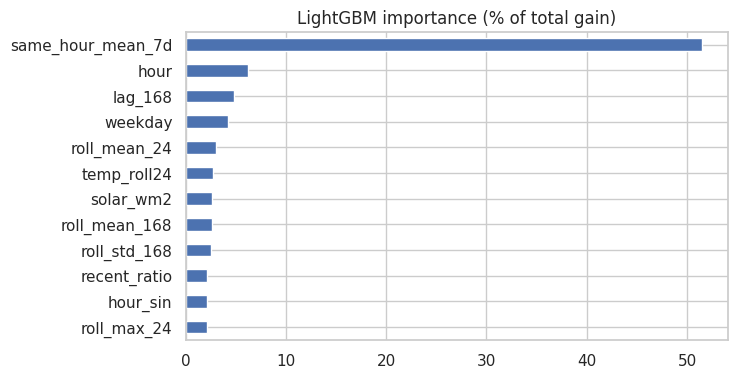

[0.36, 0.28, 0.21, 0.18, 0.18, 0.15, 0.23, 0.36, 0.36, 0.4, 0.34, 0.33, 0.34, 0.36, 0.35, 0.35, 0.36, 0.36, 0.39, 0.5, 0.42, 0.46, 0.52, 0.46]
Worst 5 days:
 2010-07-04    0.80
2010-06-06    0.68
2010-07-15    0.58
2010-07-01    0.55
2010-06-05    0.52
dtype: float64


In [59]:
cols = sets["C. Calendar + history + weather"]
m = fit_lgb(cols, best)
imp = pd.Series(m.booster_.feature_importance("gain"), index=cols)
imp = (imp / imp.sum() * 100).sort_values(ascending=False)
print(imp.head(12).round(1))
imp.head(12)[::-1].plot.barh(figsize=(7, 4), title="LightGBM importance (% of total gain)"); plt.show()

# Where does it fail? Error by hour, and on the worst days
p = preds["C. Calendar + history + weather"]
err = pd.Series(np.abs(yv - p), index=val.index)[val_mask]
print(err.groupby(err.index.hour).mean().round(2).tolist())
print("Worst 5 days:\n", err.groupby(err.index.date).mean().nlargest(5).round(2))

In [66]:
p = preds["C. Calendar + history + weather"]
dd = pd.DataFrame({"actual": val["target"], "pred": p, "imputed": val["imputed"]}, index=val.index)
daily = dd.groupby(dd.index.date).agg(actual=("actual", "sum"), pred=("pred", "sum"),
                                      imputed_hours=("imputed", "sum"))
daily["bias_kwh"] = daily["pred"] - daily["actual"]          # positive = over-predicted

lookback = data["imputed"].astype(int).rolling(168).sum().shift(24)   # imputed hours inside the feature window
daily["imputed_in_lookback"] = lookback.groupby(lookback.index.date).mean().reindex(daily.index)

worst = [pd.Timestamp(x).date() for x in ["2010-07-04", "2010-06-06", "2010-07-15", "2010-07-01", "2010-06-05"]]
print(daily.loc[worst].round(1))
print("\nValidation days containing imputed hours:\n", daily[daily["imputed_hours"] > 0][["imputed_hours"]].T)

            actual  pred  imputed_hours  bias_kwh  imputed_in_lookback
2010-07-04    25.6  20.4              0      -5.3                  0.0
2010-06-06    29.1  22.8              0      -6.4                  0.0
2010-07-15    27.2  15.8              0     -11.5                  0.0
2010-07-01    22.5  16.8              0      -5.7                  0.0
2010-06-05    33.5  25.6              0      -7.9                  0.0

Validation days containing imputed hours:
                2010-08-17  2010-08-18  2010-08-19  2010-08-20  2010-08-21  \
imputed_hours           3          24          24          24          24   

               2010-08-22  
imputed_hours          21  


In [67]:
for d_ in worst:
    prev = daily["actual"].reindex(pd.date_range(pd.Timestamp(d_) - pd.Timedelta(days=7), periods=7).date)
    print(d_, "previous 7 days (kWh/day):", prev.round(0).tolist())

print("Validation mean bias (pred - actual):", round((p - yv)[val_mask].mean(), 3), "kWh/h")

2010-07-04 previous 7 days (kWh/day): [19.0, 25.0, 23.0, 23.0, 22.0, 19.0, 19.0]
2010-06-06 previous 7 days (kWh/day): [28.0, 22.0, 21.0, 16.0, 23.0, 24.0, 33.0]
2010-07-15 previous 7 days (kWh/day): [20.0, 18.0, 19.0, 20.0, 18.0, 23.0, 23.0]
2010-07-01 previous 7 days (kWh/day): [18.0, 18.0, 16.0, 19.0, 25.0, 23.0, 23.0]
2010-06-05 previous 7 days (kWh/day): [34.0, 28.0, 22.0, 21.0, 16.0, 23.0, 24.0]
Validation mean bias (pred - actual): 0.002 kWh/h


In [68]:
imp = test["imputed"]
grp = (imp != imp.shift()).cumsum()
print("Imputed stretches in test (start, end, hours):")
print(imp[imp].groupby(grp[imp]).apply(lambda s: (s.index.min(), s.index.max(), len(s))).tolist())

hist_imp = data["imputed"].astype(int).rolling(168).sum().shift(24).reindex(test.index)
clean = (hist_imp == 0) & (~test["imputed"])
print("Test hours scored (real readings):", int((~test['imputed']).sum()),
      "| of which with fully real history:", int(clean.sum()))
print("First test hour with fully real history:", test.index[(hist_imp == 0)].min())

Imputed stretches in test (start, end, hours):
[(Timestamp('2010-09-25 04:00:00'), Timestamp('2010-09-28 18:00:00'), 87), (Timestamp('2010-11-26 21:00:00'), Timestamp('2010-11-26 21:00:00'), 1)]
Test hours scored (real readings): 2142 | of which with fully real history: 1835
First test hour with fully real history: 2010-08-30 20:00:00


In [69]:
# 1. Weekend vs weekday bias on validation (real hours only)
dd["is_weekend"] = dd.index.dayofweek >= 5
real_dd = dd[~dd["imputed"]]
print(real_dd.groupby("is_weekend").apply(
    lambda g: pd.Series({"hours": len(g), "mean_actual": g["actual"].mean(),
                         "mean_pred": g["pred"].mean(), "bias": (g["pred"] - g["actual"]).mean()})).round(3))

# 2. Was July 2010 busier than earlier Julys? (mean kWh/day)
daily_all = data["demand_kwh"].resample("D").sum()
for mth in [6, 7]:
    s = daily_all[daily_all.index.month == mth]
    print("Month", mth, s.groupby(s.index.year).mean().round(1).to_dict())


             hours  mean_actual  mean_pred   bias
is_weekend                                       
False       1509.0        0.748      0.743 -0.005
True         579.0        0.832      0.851  0.019
Month 6 {2007: 19.8, 2008: 23.9, 2009: 20.3, 2010: 23.3}
Month 7 {2007: 16.0, 2008: 19.1, 2009: 14.8, 2010: 17.3}


In [70]:
print(tab.round(3)); print("Mean validation demand:", round(yv[val_mask].mean(), 3))
print(gres.head(4).round(4)); print("Chosen:", best)
print(abl.round(3))
print(f"Days {len(diff)} | gain {diff.mean():.4f} | SE {diff.std()/np.sqrt(len(diff)):.4f} | helped {(diff>0).mean()*100:.0f}%")

                        MAE   RMSE  MAE % of mean   MAPE %  Peak MAE
Mean of training      0.597  0.668         77.369  139.543     0.581
Yesterday (lag_24)    0.402  0.611         52.141   57.461     0.491
Last week (lag_168)   0.452  0.652         58.584   74.617     0.589
7-day same-hour mean  0.365  0.504         47.372   60.769     0.451
Mean validation demand: 0.771
   num_leaves  learning_rate  min_child_samples  best_iter     MAE    RMSE
7          31           0.06                 60        169  0.3446  0.4696
4          31           0.03                 20        384  0.3454  0.4696
5          31           0.03                 60        404  0.3455  0.4710
6          31           0.06                 20        275  0.3476  0.4737
Chosen: {'num_leaves': 31, 'learning_rate': 0.06, 'min_child_samples': 60}
                                   MAE   RMSE  MAE % of mean  MAPE %  \
A. Calendar only                 0.368  0.499         47.729  61.206   
B. Calendar + history          

In [71]:
trainval = pd.concat([train, val])
colsB = calendar_feats + lag_feats
colsC = calendar_feats + lag_feats + weather_feats

def fit_final(cols, n_est, seed):
    m = lgb.LGBMRegressor(objective="regression", n_estimators=n_est, subsample=0.8,
                          subsample_freq=1, colsample_bytree=0.8, random_state=seed, verbose=-1, **best)
    return m.fit(trainval[cols], trainval["target"])

seeds = [42, 7, 123]
pB = np.mean([fit_final(colsB, 240, s).predict(test[colsB]) for s in seeds], axis=0)   # 240 ~ early-stop iterations in 5A
pC = np.mean([fit_final(colsC, 260, s).predict(test[colsC]) for s in seeds], axis=0)

yt, ht = test["target"].values, test.index.hour
cand = {
    "Mean of train+val":    np.full(len(test), trainval["target"].mean()),
    "Yesterday (lag_24)":   test["lag_24"].values,
    "Last week (lag_168)":  test["lag_168"].values,
    "7-day same-hour mean": test["same_hour_mean_7d"].values,
    "LightGBM B (no weather)": pB,
    "LightGBM C (+weather)":  pC,
}
hist_imp = data["imputed"].astype(int).rolling(168).sum().shift(24).reindex(test.index)
clean_mask = ((hist_imp == 0) & (~test["imputed"])).values

for label, mask in [("All real-reading hours", test_mask), ("Real readings AND fully real history", clean_mask)]:
    t = pd.DataFrame({k: metrics(yt, v, mask, ht) for k, v in cand.items()}).T
    print(f"\n{label}: {mask.sum()} hours, mean demand {yt[mask].mean():.3f}")
    print(t.round(3))

def dae(p, mask):
    e = pd.Series(np.abs(yt - p), index=test.index)[mask]
    return e.groupby(e.index.date).mean()
dd_ = dae(pB, test_mask) - dae(pC, test_mask)
print(f"\nWeather on TEST: days {len(dd_)} | gain {dd_.mean():.4f} | SE {dd_.std()/np.sqrt(len(dd_)):.4f} | helped {(dd_>0).mean()*100:.0f}%")


All real-reading hours: 2142 hours, mean demand 1.102
                           MAE   RMSE  MAE % of mean  MAPE %  Peak MAE
Mean of train+val        0.644  0.783         58.465  96.954     0.857
Yesterday (lag_24)       0.581  0.843         52.690  71.255     0.863
Last week (lag_168)      0.629  0.898         57.033  76.754     0.942
7-day same-hour mean     0.481  0.673         43.621  62.775     0.677
LightGBM B (no weather)  0.462  0.644         41.945  62.506     0.676
LightGBM C (+weather)    0.462  0.642         41.894  62.377     0.682

Real readings AND fully real history: 1835 hours, mean demand 1.101
                           MAE   RMSE  MAE % of mean  MAPE %  Peak MAE
Mean of train+val        0.646  0.786         58.697  98.311     0.855
Yesterday (lag_24)       0.578  0.844         52.498  72.029     0.849
Last week (lag_168)      0.635  0.907         57.714  80.261     0.950
7-day same-hour mean     0.478  0.667         43.404  64.939     0.665
LightGBM B (no weather) 

In [72]:
PEAK = [18, 19, 20, 21]
TARGET = [10, 11, 12, 13, 14, 15, 16, 17, 22, 23]
PRICE_PEAK, PRICE_OFF, CAP = 0.25, 0.15, 1.0

sim = data.loc["2010-08-26":, ["demand_kwh", "kitchen", "laundry", "heater_ac", "other", "imputed"]].copy()
sim["fc"] = pd.Series(pB, index=test.index)
sim["date"], sim["hour"] = sim.index.date, sim.index.hour
ok = sim.groupby("date").apply(lambda g: len(g) == 24 and not g["imputed"].any())
sim = sim[sim["date"].map(ok)]
print("Days simulated (complete, real readings only):", sim["date"].nunique())

def schedule_day(g, flex_cols, f, strategy):
    h, load = g["hour"].values, g["demand_kwh"].values.copy()
    flex = g[flex_cols].sum(axis=1).values / 1000           # Wh -> kWh per hour
    pk = np.isin(h, PEAK)
    moved = f * flex[pk].sum()
    if strategy == "none" or moved <= 0:
        return load
    load[pk] -= f * flex[pk]
    tgt = np.where(np.isin(h, TARGET))[0]
    score = {"fixed":    np.abs(h[tgt] - 22),
             "forecast": g["fc"].values[tgt],
             "oracle":   g["demand_kwh"].values[tgt]}[strategy]
    left = moved
    for i in tgt[np.argsort(score)]:
        add = min(CAP, left); load[i] += add; left -= add
        if left <= 1e-9: break
    assert np.isclose(load.sum(), g["demand_kwh"].sum()), "energy not conserved"
    return load

def run(flex_cols, f, strategy):
    R = []
    for _, g in sim.groupby("date"):
        h, old = g["hour"].values, g["demand_kwh"].values
        new = schedule_day(g, flex_cols, f, strategy)
        pk = np.isin(h, PEAK); p = np.where(pk, PRICE_PEAK, PRICE_OFF)
        R.append([(old*p).sum(), (new*p).sum(), (old-new)[pk].sum(), old[pk].sum(),
                  old.max(), new.max(), old[~pk].max(), new[~pk].max()])
    R = pd.DataFrame(R, columns=["c0","c1","moved","pk0","max0","max1","opmax0","opmax1"])
    return pd.Series({
        "bill_eur_day": R.c0.mean(), "saving_eur_day": (R.c0 - R.c1).mean(),
        "saving_%": (1 - R.c1.sum()/R.c0.sum())*100, "moved_kwh_day": R.moved.mean(),
        "peak_window_cut_%": R.moved.sum()/R.pk0.sum()*100,
        "daily_max_kw": R.max1.mean(), "daily_max_before": R.max0.mean(),
        "offpeak_max_kw": R.opmax1.mean(), "offpeak_max_before": R.opmax0.mean()})

Days simulated (complete, real readings only): 88


In [73]:
rows = {}
for fname, cols in {"Laundry only": ["laundry"], "Laundry + heater/AC": ["laundry", "heater_ac"]}.items():
    for f in [0.3, 0.5, 0.7]:
        rows[(fname, f)] = run(cols, f, "forecast")
res = pd.DataFrame(rows).T
print(res.round(3))

# Sanity check: every moved kWh goes from a 0.25 hour to a 0.15 hour, so saving must equal 0.10 x moved
print("Check:", np.allclose(res["saving_eur_day"], (PRICE_PEAK - PRICE_OFF) * res["moved_kwh_day"]))

                         bill_eur_day  saving_eur_day  saving_%  \
Laundry only        0.3         4.653           0.011     0.247   
                    0.5         4.653           0.019     0.411   
                    0.7         4.653           0.027     0.576   
Laundry + heater/AC 0.3         4.653           0.062     1.335   
                    0.5         4.653           0.104     2.224   
                    0.7         4.653           0.145     3.114   

                         moved_kwh_day  peak_window_cut_%  daily_max_kw  \
Laundry only        0.3          0.115              1.666         2.729   
                    0.5          0.191              2.777         2.723   
                    0.7          0.268              3.888         2.715   
Laundry + heater/AC 0.3          0.621              9.015         2.663   
                    0.5          1.035             15.026         2.631   
                    0.7          1.449             21.036         2.617   

    

In [74]:
cmp = pd.DataFrame({s: run(["laundry", "heater_ac"], 0.5, s) for s in ["none", "fixed", "forecast", "oracle"]}).T
print(cmp[["saving_eur_day", "peak_window_cut_%", "daily_max_kw", "offpeak_max_kw"]].round(3))

          saving_eur_day  peak_window_cut_%  daily_max_kw  offpeak_max_kw
none               0.000              0.000         2.732           2.475
fixed              0.104             15.026         2.674           2.620
forecast           0.104             15.026         2.631           2.544
oracle             0.104             15.026         2.581           2.478
